<a href="https://colab.research.google.com/github/roopeshscs24-maker/BIS-lab/blob/main/SystemlevelFaultCuckooSearch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install numpy matplotlib -q


========== SYSTEM FAULT DIAGNOSIS ==========
Component C 1 : FAULT-FREE
Component C 2 : FAULT-FREE
Component C 3 : FAULTY
Component C 4 : FAULTY
Component C 5 : FAULT-FREE
Component C 6 : FAULTY
Component C 7 : FAULT-FREE
Component C 8 : FAULT-FREE
Component C 9 : FAULT-FREE
Component C 10 : FAULT-FREE

========== DIAGNOSIS RESULTS ==========
Actual Faults:      [0 0 1 0 0 1 0 0 0 0]
Diagnosed Faults:   [0 0 1 1 0 1 0 0 0 0]
Correct Components: 9
Diagnosis Accuracy: 90.0 %
Diagnosis Errors: 1


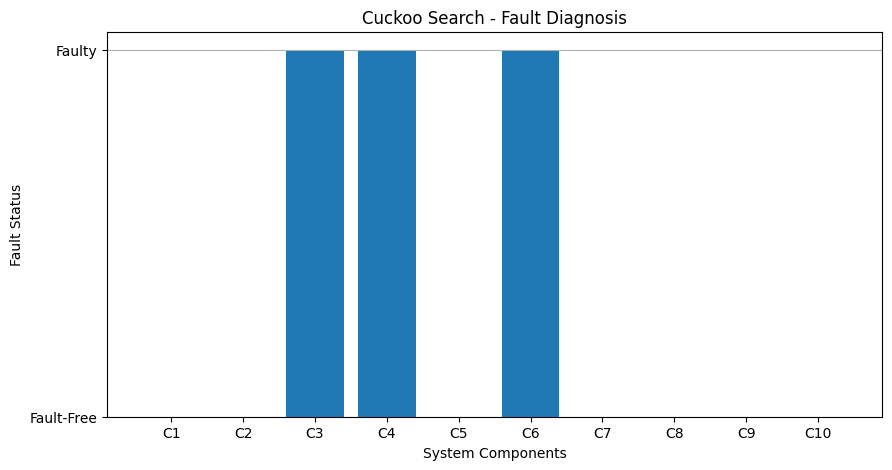

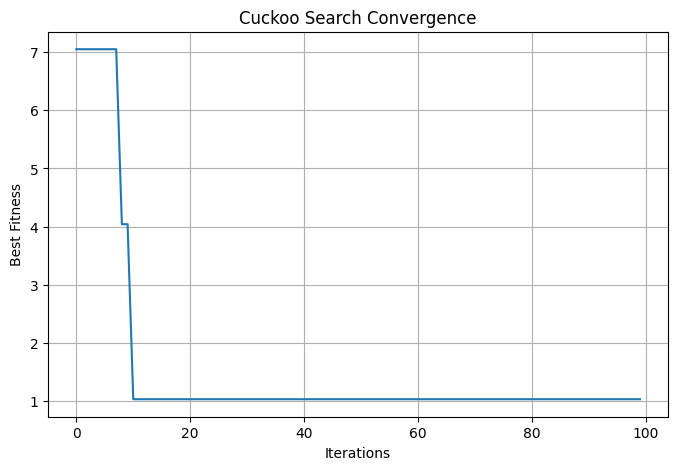

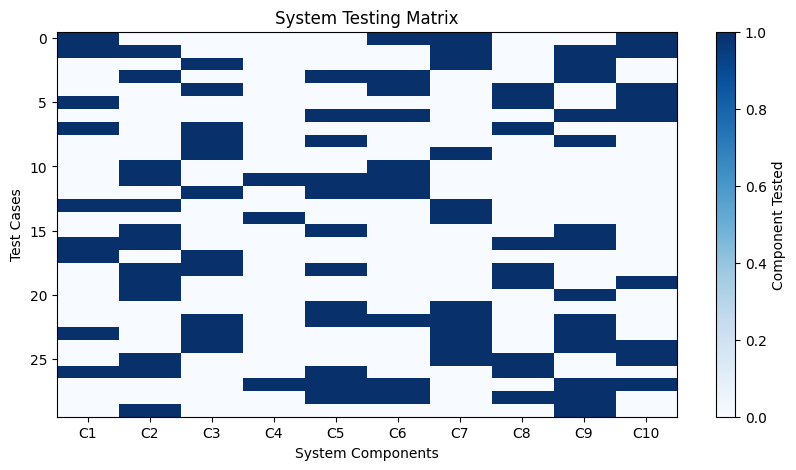

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import math

# ==========================================
# 1. SYSTEM CONFIGURATION
# ==========================================

np.random.seed(42)

n_components = 10
n_testers = 5
n_tests = 30

# Actual faulty components (used for simulation)
actual_faults = np.array([
    0, 0, 1, 0, 0, 1, 0, 0, 0, 0
])

# ==========================================
# 2. GENERATE TEST MATRIX
# ==========================================

# Each row represents one test
# Each column represents one component

test_matrix = np.zeros((n_tests, n_components))

for i in range(n_tests):

    selected = np.random.choice(
        n_components,
        size=np.random.randint(2, 6),
        replace=False
    )

    test_matrix[i, selected] = 1

# ==========================================
# 3. GENERATE TEST RESULTS
# ==========================================

# Test fails if at least one tested component is faulty

test_results = np.zeros(n_tests)

for i in range(n_tests):

    tested_components = test_matrix[i]

    if np.any(tested_components * actual_faults):
        test_results[i] = 1
    else:
        test_results[i] = 0

# ==========================================
# 4. CUCKOO SEARCH PARAMETERS
# ==========================================

n_nests = 25
max_iterations = 100

pa = 0.25       # Discovery probability
alpha = 0.1     # Step size
beta = 1.5      # Levy flight exponent

# Initialize nests
nests = np.random.rand(n_nests, n_components)

best_nest = None
best_fitness = float('inf')

fitness_history = []

# ==========================================
# 5. FITNESS FUNCTION
# ==========================================

def fitness(solution):

    # Convert continuous values into binary faults
    faults = (solution >= 0.5).astype(int)

    predicted_results = (
        test_matrix @ faults > 0
    ).astype(int)

    # Diagnosis error
    error = np.sum(
        predicted_results != test_results
    )

    # Prefer simpler fault combinations
    fault_penalty = 0.01 * np.sum(faults)

    return error + fault_penalty


# ==========================================
# 6. LEVY FLIGHT FUNCTION
# ==========================================

def levy_flight(beta):

    sigma = (
        math.gamma(1 + beta)
        * np.sin(np.pi * beta / 2)
        /
        (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma, n_components)

    v = np.random.normal(0, 1, n_components)

    step = u / (np.abs(v) ** (1 / beta))

    return step


# ==========================================
# 7. CUCKOO SEARCH ALGORITHM
# ==========================================

for iteration in range(max_iterations):

    # Evaluate each nest
    for i in range(n_nests):

        current_fitness = fitness(nests[i])

        if current_fitness < best_fitness:

            best_fitness = current_fitness

            best_nest = nests[i].copy()

    # Generate new solutions using Levy flights
    for i in range(n_nests):

        step = levy_flight(beta)

        new_solution = (
            nests[i] +
            alpha * step * (nests[i] - best_nest)
        )

        new_solution = np.clip(
            new_solution, 0, 1
        )

        # Select a random nest
        j = np.random.randint(n_nests)

        if fitness(new_solution) < fitness(nests[j]):

            nests[j] = new_solution

    # Abandon some worst nests
    n_abandon = int(pa * n_nests)

    scores = np.array([
        fitness(nest) for nest in nests
    ])

    worst_indices = np.argsort(scores)[-n_abandon:]

    for i in worst_indices:

        nests[i] = np.random.rand(n_components)

    # Update best solution
    for i in range(n_nests):

        current_fitness = fitness(nests[i])

        if current_fitness < best_fitness:

            best_fitness = current_fitness

            best_nest = nests[i].copy()

    fitness_history.append(best_fitness)


# ==========================================
# 8. FINAL FAULT DIAGNOSIS
# ==========================================

diagnosed_faults = (
    best_nest >= 0.5
).astype(int)

print("\n========== SYSTEM FAULT DIAGNOSIS ==========")

for i in range(n_components):

    if diagnosed_faults[i] == 1:

        status = "FAULTY"

    else:

        status = "FAULT-FREE"

    print("Component C", i + 1, ":", status)


# ==========================================
# 9. DIAGNOSIS ACCURACY
# ==========================================

correct = np.sum(
    diagnosed_faults == actual_faults
)

accuracy = (correct / n_components) * 100

print("\n========== DIAGNOSIS RESULTS ==========")

print("Actual Faults:     ", actual_faults)

print("Diagnosed Faults:  ", diagnosed_faults)

print("Correct Components:", correct)

print("Diagnosis Accuracy:", accuracy, "%")

print("Diagnosis Errors:",
      np.sum(diagnosed_faults != actual_faults))


# ==========================================
# 10. COMPONENT FAULT GRAPH
# ==========================================

components = [
    "C" + str(i + 1)
    for i in range(n_components)
]

plt.figure(figsize=(10, 5))

plt.bar(
    components,
    diagnosed_faults
)

plt.xlabel("System Components")

plt.ylabel("Fault Status")

plt.title("Cuckoo Search - Fault Diagnosis")

plt.yticks([0, 1], ["Fault-Free", "Faulty"])

plt.grid(axis="y")

plt.show()


# ==========================================
# 11. CONVERGENCE GRAPH
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(fitness_history)

plt.xlabel("Iterations")

plt.ylabel("Best Fitness")

plt.title("Cuckoo Search Convergence")

plt.grid(True)

plt.show()


# ==========================================
# 12. TEST RESULT VISUALIZATION
# ==========================================

plt.figure(figsize=(10, 5))

plt.imshow(
    test_matrix,
    cmap="Blues",
    aspect="auto"
)

plt.xlabel("System Components")

plt.ylabel("Test Cases")

plt.title("System Testing Matrix")

plt.xticks(
    range(n_components),
    components
)

plt.colorbar(label="Component Tested")

plt.show()